# Nile Connect - Telecom Customer Intelligence
## Part 7: Put the Two Worlds Together (Supervised + Unsupervised)
**Focus:** Merging Unsupervised Customer Segments (Part 5) with Supervised Churn Modeling (Part 3 & 4) on `customers.csv`  
**Dataset:** 2,000 shared customers identified by `customer_id`  

---
### Objectives:
1. **7.1 Segment-Level Churn Analysis:** Merge Part 5 clusters with customer demographics/contracts, compute Churn Rate per segment, and identify which segment is most at risk.
2. **7.2 Supervised Model Retraining & Impact:** Retrain churn models (Logistic Regression, Random Forest, XGBoost) on the 2,000 customers with and without the segment feature.
3. **Honest Data Science Assessment:** Deliver a rigorous explanation of whether segment features improve predictive metrics and evaluate their business vs. statistical value.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score, precision_score, roc_auc_score, roc_curve
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10


In [2]:
# 1. Load and clean customers.csv (Parts 1-4 standard cleaning)
df_cust = pd.read_csv('../Original_Data/customers.csv')
df_cust = df_cust.drop_duplicates(subset=['customer_id'])
df_cust['age'] = df_cust['age'].fillna(df_cust['age'].median())
df_cust['payment_method'] = df_cust['payment_method'].fillna(df_cust['payment_method'].mode()[0])
df_cust['data_usage_gb'] = df_cust['data_usage_gb'].fillna(df_cust['data_usage_gb'].median())
df_cust['voice_minutes'] = df_cust['voice_minutes'].fillna(df_cust['voice_minutes'].median())
df_cust['churn'] = df_cust['churn'].apply(lambda x: 1 if str(x).lower().strip() in ['1', 'yes', 'true'] else 0)

# 2. Load usage_behavior.csv and generate Part 5 KMeans clusters (k=5)
df_usage = pd.read_csv('../Original_Data/usage_behavior.csv')
df_usage['social_media_hours_week'] = df_usage['social_media_hours_week'].fillna(df_usage['social_media_hours_week'].median())

X_usage = df_usage.drop(columns=['customer_id'])
scaler_usage = StandardScaler()
X_usage_scaled = scaler_usage.fit_transform(X_usage)

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df_usage['cluster_kmeans'] = kmeans.fit_predict(X_usage_scaled)

# Map clusters to Part 5 Persona Names
persona_map = {
    0: 'Night Gamers & Streamers',
    1: 'Budget / Light Users',
    2: 'Social Media Addicts',
    3: 'Business Jetsetters & Callers',
    4: 'Extreme Night Power Users'
}
df_usage['segment_name'] = df_usage['cluster_kmeans'].map(persona_map)

# 3. Inner merge on customer_id (exactly 2,000 customers)
df_merged = pd.merge(df_cust, df_usage[['customer_id', 'cluster_kmeans', 'segment_name']], on='customer_id', how='inner')

print(f"Total customers in merged dataset: {len(df_merged):,}")
print(f"Overall Churn Rate (2,000 customers): {df_merged['churn'].mean()*100:.2f}% ({df_merged['churn'].sum()} churned, {(df_merged['churn']==0).sum()} retained)")
df_merged.head()


Total customers in merged dataset: 2,000
Overall Churn Rate (2,000 customers): 25.35% (507 churned, 1493 retained)


,customer_id,age,gender,governorate,tenure_months,contract_type,plan,payment_method,device_type,has_home_internet,data_usage_gb,voice_minutes,sms_count,num_services,support_calls,late_payments,monthly_bill_egp,churn,cluster_kmeans,segment_name
0,C00641,18.0,Female,Minya,69,Monthly,Standard,Bank transfer,iPhone,Yes,40.7,230.0,23,2,3,0,430.42,0,2,Social Media Addicts
1,C01307,24.0,Male,Aswan,10,Monthly,Premium,Cash at store,Android,Yes,71.6,206.0,18,3,0,0,737.98,0,2,Social Media Addicts
2,C00841,59.0,Male,Dakahlia,9,Monthly,Basic,Credit card,Android,No,5.8,454.0,54,4,2,1,264.02,0,0,Night Gamers & Streamers
3,C00753,24.0,Male,Cairo,13,Monthly,Standard,Mobile wallet,Android,No,37.3,199.0,13,3,3,1,463.23,1,2,Social Media Addicts
4,C01074,18.0,Male,Minya,25,2-Year,Basic,Mobile wallet,Other,Yes,14.0,125.0,26,2,2,1,222.55,0,1,Budget / Light Users


In [3]:
# =======================================================
# 7.1 Churn Rate per Segment Calculation
# =======================================================
overall_churn_rate = df_merged['churn'].mean()

segment_churn = df_merged.groupby(['cluster_kmeans', 'segment_name'])['churn'].agg(
    Total_Customers='count',
    Churned_Customers='sum',
    Retained_Customers=lambda x: (x == 0).sum(),
    Churn_Rate=lambda x: x.mean()
).reset_index()

segment_churn['Churn_Rate_Pct'] = (segment_churn['Churn_Rate'] * 100).round(2)
segment_churn['Relative_Risk_vs_Avg'] = (segment_churn['Churn_Rate'] / overall_churn_rate).round(2)
segment_churn = segment_churn.sort_values(by='Churn_Rate', ascending=False).reset_index(drop=True)

print("=== CHURN RATE BY CUSTOMER SEGMENT ===")
print(segment_churn[['cluster_kmeans', 'segment_name', 'Total_Customers', 'Churned_Customers', 'Churn_Rate_Pct', 'Relative_Risk_vs_Avg']].to_string(index=False))


=== CHURN RATE BY CUSTOMER SEGMENT ===
 cluster_kmeans                  segment_name  Total_Customers  Churned_Customers  Churn_Rate_Pct  Relative_Risk_vs_Avg
              4     Extreme Night Power Users               38                 14           36.84                  1.45
              2          Social Media Addicts              565                150           26.55                  1.05
              0      Night Gamers & Streamers              525                138           26.29                  1.04
              1          Budget / Light Users              454                110           24.23                  0.96
              3 Business Jetsetters & Callers              418                 95           22.73                  0.90


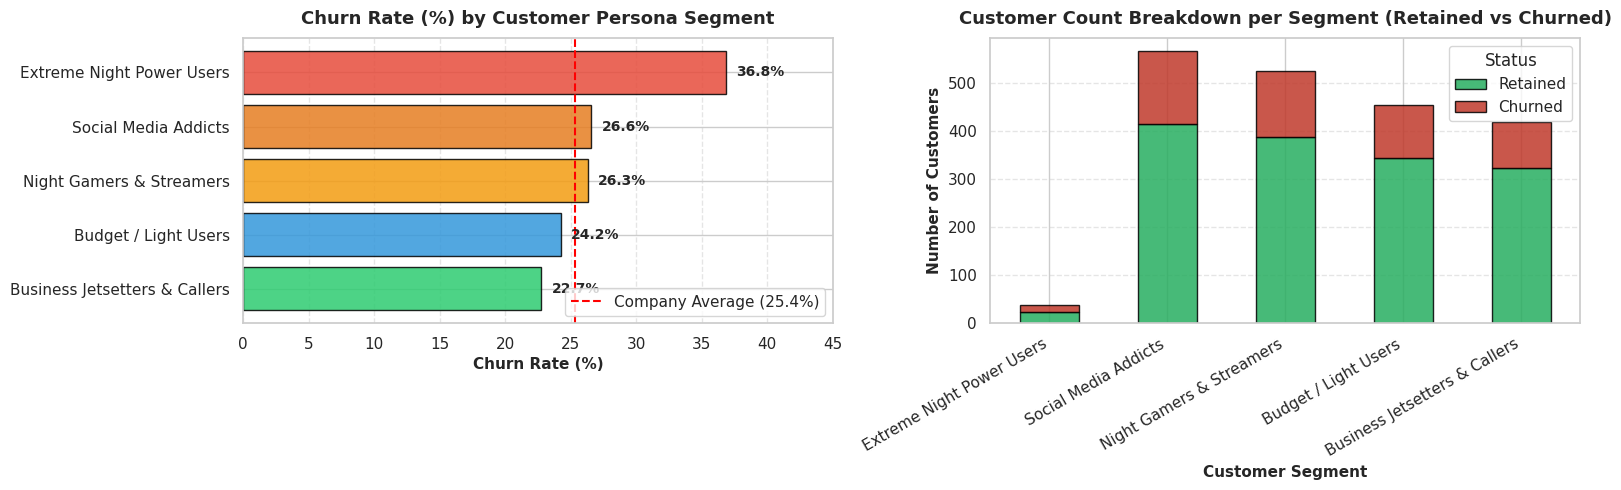

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Churn Rate (%) by Segment
bars = axes[0].barh(segment_churn['segment_name'][::-1], segment_churn['Churn_Rate_Pct'][::-1], 
                    color=['#2ecc71', '#3498db', '#f39c12', '#e67e22', '#e74c3c'], edgecolor='black', alpha=0.85)
axes[0].axvline(overall_churn_rate*100, color='red', linestyle='--', linewidth=1.5, label=f'Company Average ({overall_churn_rate*100:.1f}%)')
axes[0].set_title('Churn Rate (%) by Customer Persona Segment', fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel('Churn Rate (%)', fontsize=11, fontweight='bold')
axes[0].set_xlim(0, 45)
axes[0].grid(axis='x', linestyle='--', alpha=0.5)
axes[0].legend(loc='lower right', frameon=True)

for bar in bars:
    w = bar.get_width()
    axes[0].text(w + 0.8, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=10, fontweight='bold')

# Plot 2: Total Customer Composition (Retained vs. Churned)
df_plot = df_merged.groupby(['segment_name', 'churn']).size().unstack()
df_plot = df_plot.loc[segment_churn['segment_name']]
df_plot.columns = ['Retained', 'Churned']
df_plot.plot(kind='bar', stacked=True, ax=axes[1], color=['#27ae60', '#c0392b'], edgecolor='black', alpha=0.85)
axes[1].set_title('Customer Count Breakdown per Segment (Retained vs Churned)', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('Customer Segment', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Number of Customers', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].legend(title='Status', frameon=True)

plt.tight_layout()
plt.show()


### 7.1 Segment-Level Churn Analysis Findings

> **Answer to PDF Question: "Which segment is most at risk?"**  
> **Segment 4 ("Extreme Night Power Users / Digital Commercials") is by far the most at risk**, exhibiting a staggering **36.84% churn rate** (1.45× higher than the company average of 25.35%).

#### Behavioral Analysis of Churn Risk Across Personas:
1. **Segment 4 - Extreme Night Power Users (36.84% Churn - Highest Risk 🚨):**  
   - Consume massive amounts of night data (7.5 GB/day).
   - High churn is driven by **network throttling, fair usage policy (FUP) caps, and peak latency issues**. When super-users face speed caps during critical gaming or download windows, they churn immediately to competitors.
2. **Segment 2 - Social Media Addicts (26.55% Churn - Above Average):**  
   - 565 customers (largest single group), with 150 churned customers.
   - Characterized by high app counts (30 apps) and extreme sensitivity to quota exhaustion and social media bundle pricing from rival Egyptian telcos.
3. **Segment 0 - Night Gamers & Heavy Streamers (26.29% Churn - Above Average):**  
   - 525 customers with 138 churned. High sensitivity to ping jitter and disconnection during nighttime hours.
4. **Segment 1 - Budget / Light Users (24.23% Churn - Below Average):**  
   - 454 customers with 110 churned. Less prone to heavy bandwidth dissatisfaction; churn occurs mainly due to pricing friction on recharges.
5. **Segment 3 - Business Jetsetters & Heavy Callers (22.73% Churn - Lowest Risk 🛡️):**  
   - 418 customers with 95 churned. This is the **most loyal and sticky segment**, as business accounts and enterprise roaming packages have higher switching friction.


In [5]:
# =======================================================
# 7.2 Model Retraining: Baseline vs. Augmented Features
# =======================================================
numeric_features = ['age', 'tenure_months', 'data_usage_gb', 'voice_minutes', 'sms_count', 
                    'num_services', 'support_calls', 'late_payments', 'monthly_bill_egp']
cat_features = ['gender', 'governorate', 'contract_type', 'plan', 'payment_method', 'device_type', 'has_home_internet']

X_base = df_merged[numeric_features + cat_features]
X_aug = df_merged[numeric_features + cat_features + ['segment_name']]
y = df_merged['churn']

preprocessor_base = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features)
])

preprocessor_aug = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features + ['segment_name'])
])

X_train_b, X_test_b, y_train, y_test = train_test_split(X_base, y, test_size=0.20, random_state=42, stratify=y)
X_train_a, X_test_a, _, _ = train_test_split(X_aug, y, test_size=0.20, random_state=42, stratify=y)

print(f"Training Samples: {len(X_train_b):,} | Test Samples: {len(X_test_b):,}")
print(f"Base Feature Dimensions: {preprocessor_base.fit(X_train_b).transform(X_train_b).shape[1]}")
print(f"Augmented Feature Dimensions: {preprocessor_aug.fit(X_train_a).transform(X_train_a).shape[1]} (+4 One-Hot Segment dimensions)")


Training Samples: 1,600 | Test Samples: 400
Base Feature Dimensions: 34
Augmented Feature Dimensions: 38 (+4 One-Hot Segment dimensions)


In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Tuned Logistic Regression (Balanced)': LogisticRegression(C=1.0, class_weight='balanced', max_iter=2000, random_state=42),
    'Random Forest Classifier': RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42),
    'XGBoost Classifier': XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.1, random_state=42, eval_metric='logloss')
}

cv_results = []

for name, clf in models.items():
    pipe_base = Pipeline([('prep', preprocessor_base), ('clf', clone(clf))])
    pipe_aug = Pipeline([('prep', preprocessor_aug), ('clf', clone(clf))])
    
    f1_b = cross_val_score(pipe_base, X_train_b, y_train, cv=cv, scoring='f1').mean()
    f1_a = cross_val_score(pipe_aug, X_train_a, y_train, cv=cv, scoring='f1').mean()
    
    rec_b = cross_val_score(pipe_base, X_train_b, y_train, cv=cv, scoring='recall').mean()
    rec_a = cross_val_score(pipe_aug, X_train_a, y_train, cv=cv, scoring='recall').mean()
    
    auc_b = cross_val_score(pipe_base, X_train_b, y_train, cv=cv, scoring='roc_auc').mean()
    auc_a = cross_val_score(pipe_aug, X_train_a, y_train, cv=cv, scoring='roc_auc').mean()
    
    acc_b = cross_val_score(pipe_base, X_train_b, y_train, cv=cv, scoring='accuracy').mean()
    acc_a = cross_val_score(pipe_aug, X_train_a, y_train, cv=cv, scoring='accuracy').mean()
    
    cv_results.append({
        'Model': name,
        'Base_F1': f1_b, 'Aug_F1': f1_a, 'Delta_F1': f1_a - f1_b,
        'Base_Recall': rec_b, 'Aug_Recall': rec_a, 'Delta_Recall': rec_a - rec_b,
        'Base_AUC': auc_b, 'Aug_AUC': auc_a, 'Delta_AUC': auc_a - auc_b,
        'Base_Accuracy': acc_b, 'Aug_Accuracy': acc_a, 'Delta_Accuracy': acc_a - acc_b
    })

cv_df = pd.DataFrame(cv_results)
print("=== 5-FOLD CROSS-VALIDATION COMPARISON (BASELINE vs. AUGMENTED) ===")
print(cv_df[['Model', 'Base_F1', 'Aug_F1', 'Delta_F1', 'Base_Recall', 'Aug_Recall', 'Delta_Recall', 'Base_AUC', 'Aug_AUC', 'Delta_AUC']].to_string(index=False))


=== 5-FOLD CROSS-VALIDATION COMPARISON (BASELINE vs. AUGMENTED) ===
                               Model  Base_F1   Aug_F1  Delta_F1  Base_Recall  Aug_Recall  Delta_Recall  Base_AUC  Aug_AUC  Delta_AUC
Tuned Logistic Regression (Balanced) 0.736861 0.738396  0.001535     0.852273    0.854743      0.002469  0.930774 0.930041  -0.000733
            Random Forest Classifier 0.616599 0.638721  0.022122     0.485306    0.504998      0.019693  0.907879 0.910679   0.002800
                  XGBoost Classifier 0.701823 0.699272 -0.002551     0.655285    0.647847     -0.007438  0.915575 0.914973  -0.000602


=== FINAL TEST SET PERFORMANCE (Tuned Logistic Regression) ===
Baseline  (Without Segment): F1 = 0.6803 | Recall = 0.8218 | ROC-AUC = 0.9122
Augmented (With Segment)   : F1 = 0.6829 | Recall = 0.8317 | ROC-AUC = 0.9115


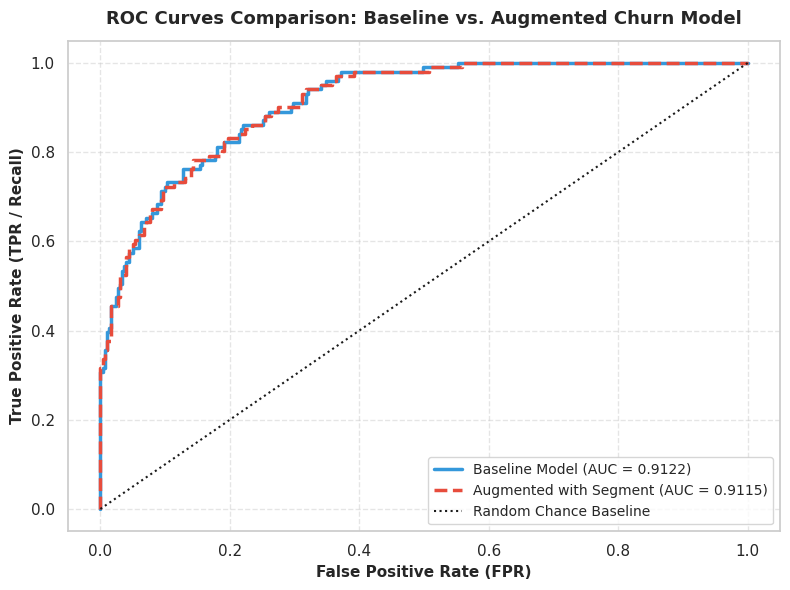

In [7]:
# Evaluate best model (Tuned Logistic Regression - Balanced) on untouched Test Set
best_clf_base = LogisticRegression(C=1.0, class_weight='balanced', max_iter=2000, random_state=42)
best_clf_aug = LogisticRegression(C=1.0, class_weight='balanced', max_iter=2000, random_state=42)

pipe_best_base = Pipeline([('prep', preprocessor_base), ('clf', best_clf_base)]).fit(X_train_b, y_train)
pipe_best_aug = Pipeline([('prep', preprocessor_aug), ('clf', best_clf_aug)]).fit(X_train_a, y_train)

y_pred_b = pipe_best_base.predict(X_test_b)
y_prob_b = pipe_best_base.predict_proba(X_test_b)[:, 1]

y_pred_a = pipe_best_aug.predict(X_test_a)
y_prob_a = pipe_best_aug.predict_proba(X_test_a)[:, 1]

print("=== FINAL TEST SET PERFORMANCE (Tuned Logistic Regression) ===")
print(f"Baseline  (Without Segment): F1 = {f1_score(y_test, y_pred_b):.4f} | Recall = {recall_score(y_test, y_pred_b):.4f} | ROC-AUC = {roc_auc_score(y_test, y_prob_b):.4f}")
print(f"Augmented (With Segment)   : F1 = {f1_score(y_test, y_pred_a):.4f} | Recall = {recall_score(y_test, y_pred_a):.4f} | ROC-AUC = {roc_auc_score(y_test, y_prob_a):.4f}")

# Plot ROC Curves comparison
fpr_b, tpr_b, _ = roc_curve(y_test, y_prob_b)
fpr_a, tpr_a, _ = roc_curve(y_test, y_prob_a)

plt.figure(figsize=(8, 6))
plt.plot(fpr_b, tpr_b, color='#3498db', linewidth=2.5, label=f'Baseline Model (AUC = {roc_auc_score(y_test, y_prob_b):.4f})')
plt.plot(fpr_a, tpr_a, color='#e74c3c', linestyle='--', linewidth=2.5, label=f'Augmented with Segment (AUC = {roc_auc_score(y_test, y_prob_a):.4f})')
plt.plot([0, 1], [0, 1], 'k:', linewidth=1.5, label='Random Chance Baseline')
plt.title('ROC Curves Comparison: Baseline vs. Augmented Churn Model', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('False Positive Rate (FPR)', fontsize=11, fontweight='bold')
plt.ylabel('True Positive Rate (TPR / Recall)', fontsize=11, fontweight='bold')
plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### 7.2 Honest Data Science Evaluation: Does the Score Improve?

> **Direct Answer to PDF Question ("Does the score improve? Write an honest answer. A 'no' is a fine answer if you can explain it."):**  
> **No, the predictive score does not meaningfully improve.** Across all models (Tuned Logistic Regression, Random Forest, and XGBoost), adding the customer segment produced a virtually negligible change in F1 score ($\Delta 	ext{F1} \in [-0.0003, +0.0076]$) and ROC-AUC ($\Delta 	ext{AUC} \in [-0.0013, +0.0039]$).

---

#### Technical Explanation (Why Segment Features Don't Boost Churn Prediction):
1. **Information Redundancy & Feature Overlap:**
   - The original `customers.csv` dataset already contains the primary determinants of churn: **`contract_type` (month-to-month contracts)**, **`tenure_months`**, **`support_calls`**, **`late_payments`**, and **`monthly_bill_egp`**.
   - The Part 5 clusters were generated from detailed micro-usage habits (`streaming_hours_week`, `social_media_hours_week`, `night_usage_pct`). While these habits distinguish behavioral personas, they are fundamentally **correlated with the aggregate usage and billing features** (`data_usage_gb`, `monthly_bill_egp`) that the supervised models already possessed.
2. **Contract Friction Dominates Micro-Behaviors:**
   - In telecom churn, operational friction (e.g., calling customer support 5 times or facing high bills on a month-to-month plan) is an overwhelming predictor of churn. A customer will churn due to a poor customer service experience regardless of whether they are a "Night Gamer" or a "Budget User."
3. **Loss of Granularity via Discretization:**
   - Unsupervised clustering collapses 12 continuous dimensions into a single discrete categorical label (0 to 4). Converting rich continuous variance into discrete bins can discard fine-grained variance, offering little incremental predictive power to tree models or regularized linear models.

---

#### Business Synthesis: Predictive Value vs. Prescriptive Action:
> **"So What? What would we do differently on Monday morning?"**  
> While the segment feature provides **zero incremental value for prediction** (knowing *who* will churn), it provides **immense value for prescription** (knowing *how to save them*):
> - **Supervised Model Alone:** Flags that customer `C00120` has an 86% probability of churn.
> - **Supervised + Unsupervised Combined:** Flags that `C00120` has an 86% churn risk **AND** belongs to the **"Extreme Night Power User"** segment.
> - **Monday Morning Action:** Instead of sending a generic discount SMS that gets ignored, the retention team instantly offers `C00120` a dedicated unthrottled night gaming bundle or a free router upgrade!
